# Seizures analysis

In [5]:
%matplotlib inline
# Data integration libraries
from pathlib import Path
import sys

# Data analysis libraries
import mne
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Data visualization and control libraries
from IPython.display import display
import time
import tempfile

In [6]:
# Locate code from all the implementation root
implementation_root = Path("../..").resolve()
sys.path.append(str(implementation_root))

# TUH Corpus structure
from src.core.data_config import BASE_PATH, CORPUS_PATHS, SEIZURE_KEYWORDS, ARTIFACT_KEYWORDS, OUTPUTS_DIR
from src.core.data_splitter import (
    grouped_split_from_labels, get_or_compute_labeled_split, split_balance_report
)
from src.utils.patient_registry import load_registry, forced_for, REG_PATH

print("Path of all the Corpus:\n", BASE_PATH, "\n", CORPUS_PATHS, "\n", SEIZURE_KEYWORDS)
SEIZURE_KEYWORKDS_BY = {
                        'seiz': {'seiz'},
                        'bckg': {'bckg'},    
                    }

# EDF visualization
mne.viz.set_browser_backend("matplotlib")

Path of all the Corpus:
 /mnt/d/tuh_eeg 
 {'all_corpus': PosixPath('tuh_eeg/v2.0.2'), 'artifact': PosixPath('tuh_eeg_artifact/v3.0.1'), 'epilepsy': PosixPath('tuh_eeg_epilepsy/v3.1.0'), 'seizure': PosixPath('tuh_eeg_seizure/v2.0.6'), 'events': PosixPath('tuh_eeg_events/v2.0.1')} 
 {'focal': {'fnsz', 'spsz', 'cpsz'}, 'generalized_toniclonic': {'mysz', 'absz', 'tcsz', 'gnsz', 'tnsz'}}
Using matplotlib as 2D backend.


## TUH EEG Seizure Corpus EDA


This subset contains annotations different artifacts:
- Tonic seizure
- Complex partial seizure
- Generalized non-specific seizure
- Focal non-specific seizure

In [7]:
# Pandas table display options
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 20)
pd.set_option("display.width", 1000)

### EDF files

In [9]:
P = Path(OUTPUTS_DIR) / "eda"
P.mkdir(exist_ok=True)
def cached(path, fn):
    return pd.read_parquet(path) if path.exists() else (lambda d: (d.to_parquet(path), d)[1])(fn())

In [10]:
# Corpus signal data
def get_edf_data(base_path, corpus_name, n_seconds=10):
    """
    Returns all signal parameters of a specific corpus.
    """
    corpus_path = base_path / CORPUS_PATHS[corpus_name]
    montages = [
        "01_tcp_ar", "02_tcp_le", "03_tcp_ar_a", "04_tcp_le_a",
        "05_tcp_ar_b", "06_tcp_le_b", "07_tcp_ar_c", "08_tcp_le_c"
    ]

    registers = []

    for session in corpus_path.rglob("*.edf"):
        montage = session.parent.name if session.parent.name in montages else None
        document_name = Path(session.name).stem
        session_id = next((part for part in document_name.split("_") if part.startswith("s") and part[1:].isdigit()), None)
        pacient = next((part for part in document_name.split("_") if len(part) == 8 and part.isalpha()), None)
        session_section = next((part for part in document_name.split("_") if part.startswith("t") and part[1:].isdigit()), None)

        # Load EDF file data (Preload = False)
        mne.set_log_level("WARNING")
        edf_data = mne.io.read_raw_edf(session, preload=False, verbose="WARNING")
        
        registers.append({
            "Corpus": corpus_name,
            "Montage": montage,
            "Session": session_id,
            "Patient": pacient,
            "Section": session_section,
            "Channels": edf_data.ch_names,
            "Amount of channels": len(edf_data.ch_names),
            "Sampling frequency [Hz]": edf_data.info["sfreq"],
            "Duration [s]": edf_data.times[-1] if len(edf_data.times) > 0 else np.nan,
            "Total amount of sampling data": edf_data.n_times,
            "Path": session,
        })

    return pd.DataFrame(registers)

# EDFs Data extraction
signal_sessions_corpus_df = get_edf_data(BASE_PATH, "seizure")

In [11]:
signal_sessions_corpus_df = cached(
    P/"edf_index.parquet",
    lambda: get_edf_data(BASE_PATH, "seizure").assign(Path=lambda d: d["Path"].astype(str)))
signal_sessions_corpus_df["Path"] = signal_sessions_corpus_df["Path"].map(Path)

In [12]:
# Visualization of previews extracted data
print(">> Sessions database preview")
display(signal_sessions_corpus_df.head(5))

>> Sessions database preview


,Corpus,Montage,Session,Patient,Section,Channels,Amount of channels,Sampling frequency [Hz],Duration [s],Total amount of sampling data,Path
0,seizure,02_tcp_le,s001,aaaaaajy,t000,"[EEG FP1-LE, EEG...",33,250.0,1749.9960,437500,/mnt/d/tuh_eeg/t...
1,seizure,01_tcp_ar,s002,aaaaaajy,t000,"[EEG FP1-REF, EE...",32,400.0,19.9975,8000,/mnt/d/tuh_eeg/t...
2,seizure,01_tcp_ar,s002,aaaaaajy,t001,"[EEG FP1-REF, EE...",32,400.0,6.9975,2800,/mnt/d/tuh_eeg/t...
3,seizure,01_tcp_ar,s002,aaaaaajy,t002,"[EEG FP1-REF, EE...",32,400.0,271.9975,108800,/mnt/d/tuh_eeg/t...
4,seizure,01_tcp_ar,s003,aaaaaajy,t000,"[EEG FP1-REF, EE...",32,400.0,233.9975,93600,/mnt/d/tuh_eeg/t...


#### EDF Characteristics


>> Distribution of the sampling frequency


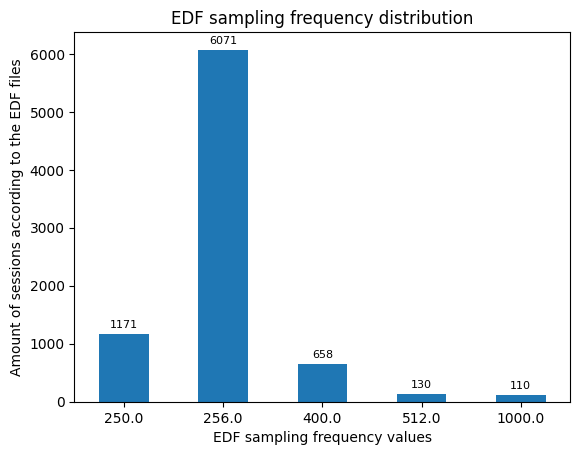


>> Distribution of the amount of channels


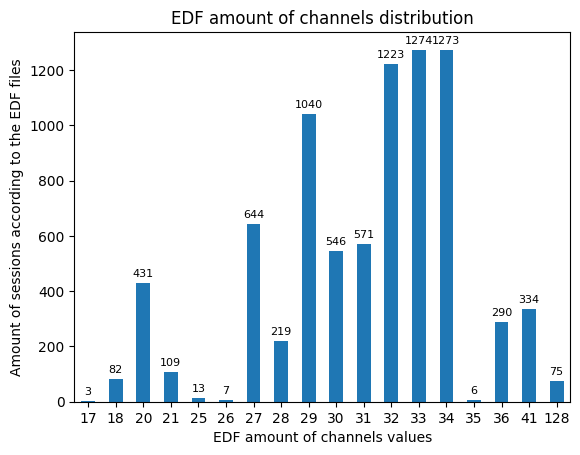


>> Channel matrix preview


Amount of channels,17,18,20,21,25,26,27,28,29,30,31,32,33,34,35,36,41,128,Total files,N variants present
Channels,,,,,,,,,,,,,,,,,,,,
EEG C3-REF,3,82,431,109,13,7,644,219,1040,546,571,1208,1050,1273,6,290,0,75,7567,17
EEG C4-REF,3,82,431,109,13,7,644,219,1040,546,571,1208,1050,1273,6,290,0,75,7567,17
EEG CZ-REF,3,82,431,109,13,7,644,219,1040,546,571,1208,1050,1273,6,290,0,75,7567,17
EEG F3-REF,3,82,431,109,13,7,644,219,1040,546,571,1208,1050,1273,6,290,0,75,7567,17
EEG F4-REF,3,82,431,109,13,7,644,219,1040,546,571,1208,1050,1273,6,290,0,75,7567,17


In [13]:
%matplotlib inline
## EDA Visualization
# General function to plot visualization for the given characteristic of the EDF Artifact corpus analysis
def plot_visualization(column_name, analyzed_parameter):
    """Plot visualization for the given dataframe column"""
    data = signal_sessions_corpus_df[column_name].value_counts().sort_index()
    axes = pd.DataFrame(data).reset_index().plot.bar(
        x=column_name,
        rot=0,
        title=f"EDF {analyzed_parameter} distribution",
        xlabel=f"EDF {analyzed_parameter} values",
        ylabel="Amount of sessions according to the EDF files",
        legend=False,
    )

    for container in axes.containers:
        axes.bar_label(container, label_type="edge", fontsize=8, padding=3)

    return axes

# Frecuency distribution of the sampling frequency
print("\n>> Distribution of the sampling frequency")
plot_visualization("Sampling frequency [Hz]", "sampling frequency")
plt.show()

# Channels distribution - examination of correct data channels
print("\n>> Distribution of the amount of channels")
plot_visualization("Amount of channels", "amount of channels")
plt.show()

# Examination of representative channels accordint to the amount found by the distribution
exploded = signal_sessions_corpus_df[["Amount of channels", "Channels"]].explode("Channels").sort_values(by="Amount of channels").reset_index(drop=True)
channel_matrix = pd.crosstab(exploded["Channels"], exploded["Amount of channels"])
channel_matrix["Total files"] = channel_matrix.drop(columns=[c for c in channel_matrix.columns if c == "Total files"], errors="ignore").sum(axis=1)
channel_matrix["N variants present"] = (channel_matrix.drop(columns="Total files") > 0).sum(axis=1)
channel_matrix = channel_matrix.sort_values(["N variants present", "Total files"], ascending=False)
print("\n>> Channel matrix preview")
display(channel_matrix.head(5))

#### Preview of EDF content


>> Sessions with 128 channels

>> Plotting a sample EDF file from the Artifact corpus with 128 channels
<Info | 8 non-empty values
 bads: []
 ch_names: EEG FP1-REF, EEG FP2-REF, EEG F3-REF, EEG F4-REF, EEG C3-REF, ...
 chs: 128 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 200.0 Hz
 meas_date: 2005-01-01 00:00:00 UTC
 nchan: 128
 projs: []
 sfreq: 400.0 Hz
 subject_info: <subject_info | his_id: aaaaabjt, sex: 2, last_name: aaaaabjt>
>
Channels: ['EEG FP1-REF', 'EEG FP2-REF', 'EEG F3-REF', 'EEG F4-REF', 'EEG C3-REF', 'EEG C4-REF', 'EEG P3-REF', 'EEG P4-REF', 'EEG O1-REF', 'EEG O2-REF', 'EEG F7-REF', 'EEG F8-REF', 'EEG T3-REF', 'EEG T4-REF', 'EEG T5-REF', 'EEG T6-REF', 'EEG FZ-REF', 'EEG CZ-REF', 'EEG PZ-REF', 'EEG 20-REF', 'EEG 21-REF', 'EEG 22-REF', 'EEG 23-REF', 'EEG 24-REF', 'EEG 25-REF', 'EEG 26-REF', 'EEG 27-REF', 'EEG 28-REF', 'EEG 29-REF', 'EEG 30-REF', 'EEG 31-REF', 'EEG 32-REF', 'EEG 33-REF', 'EEG 34-REF', 'EEG 35-REF', 'EEG 36-REF', 'EEG 37-REF', 'EEG 38-REF', 'E

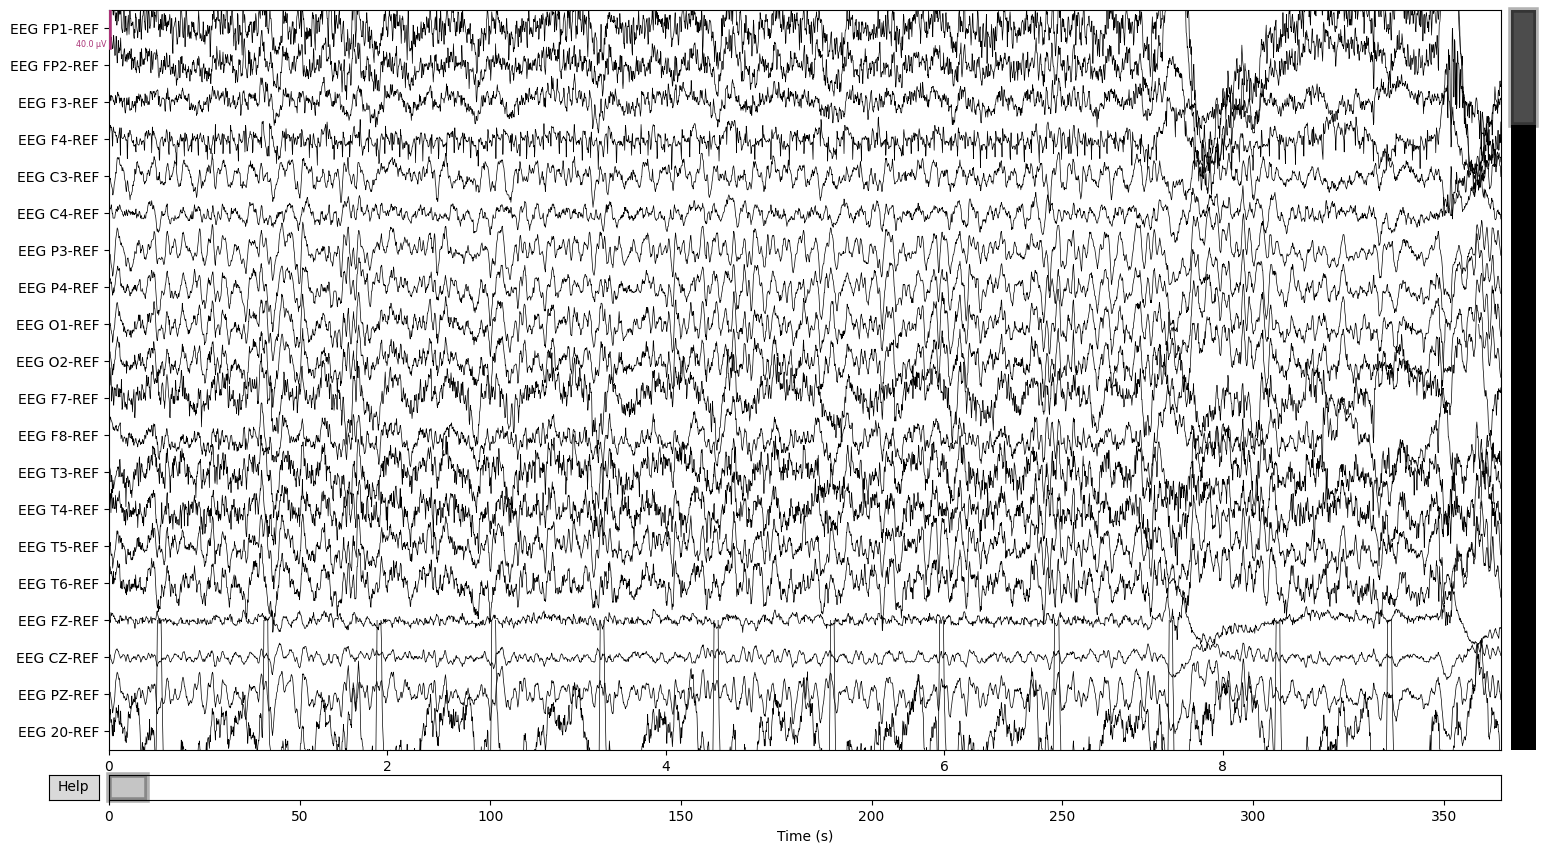

In [14]:
%matplotlib qt

# Manual analysis of sessions with 128 channels to determine the most representative channels for the corpus
print("\n>> Sessions with 128 channels")
filtered_signals = signal_sessions_corpus_df.loc[signal_sessions_corpus_df["Amount of channels"] == 128]

print("\n>> Plotting a sample EDF file from the Artifact corpus with 128 channels")
raw = mne.io.read_raw_edf(
    filtered_signals["Path"].iloc[0],
    preload=False,
    verbose="WARNING",
)
print(raw.info)
print("Channels:", raw.ch_names)
print("Channel count:", len(raw.ch_names))

raw.plot()

#### Patients distribution and characteristics

In [15]:
# Sessions reported per patient
print("\n>> Sessions per patient")
sessions_per_patient = signal_sessions_corpus_df["Patient"].value_counts()
display(sessions_per_patient.describe())

# Amount of sessions per patient
print("\n>> Sessions per patient database (head)")
display(signal_sessions_corpus_df["Patient"].value_counts().head(30))


>> Sessions per patient


count    675.000000
mean      12.059259
std       26.169603
min        1.000000
25%        1.000000
50%        3.000000
75%       12.000000
max      414.000000
Name: count, dtype: float64


>> Sessions per patient database (head)


Patient
aaaaahie    414
aaaaaoek    284
aaaaamnd    156
aaaaagbf    138
aaaaanme    105
aaaaapks     97
aaaaaoya     96
aaaaamqq     94
aaaaamva     88
aaaaagxr     88
aaaaamhb     84
aaaaaskf     81
aaaaatki     81
aaaaaqtl     75
aaaaajqo     74
aaaaaool     71
aaaaardk     66
aaaaadmi     64
aaaaambs     64
aaaaarsp     63
aaaaaogd     61
aaaaatlp     61
aaaaaroo     60
aaaaapnl     58
aaaaates     58
aaaaaovm     54
aaaaandx     53
aaaaaqek     53
aaaaaqtx     53
aaaaamqy     52
Name: count, dtype: int64

### Annotations files

In [16]:
## Annotations
# Format analysis of the annotations
path = signal_sessions_corpus_df["Path"].iloc[0].with_suffix(".csv")

text = path.read_text(encoding="utf-8", errors="replace")
comments = [line for line in text.splitlines() if line.startswith("#")]
print(comments)

ann = pd.read_csv(
    path,
    sep=",", 
    comment="#"
)

display(ann.head(5))

['# version = csv_v1.0.0', '# bname = aaaaaajy_s001_t000', '# duration = 1750.0000 secs', '# montage_file = 02_tcp_le_montage.txt', '#']


,channel,start_time,stop_time,label,confidence
0,FP1-F7,57.9964,196.0107,gnsz,1.0
1,F7-T3,57.9964,196.0107,gnsz,1.0
2,T3-T5,57.9964,196.0107,gnsz,1.0
3,T5-O1,57.9964,196.0107,gnsz,1.0
4,FP2-F8,42.9994,57.9846,fnsz,1.0


In [17]:
# Corpus annotations data
def get_csv_data(base_path, corpus_name, binary = False):
    """
    Returns all signal annotation marks of a specific corpus.
    """
    corpus_path = base_path / CORPUS_PATHS[corpus_name]
    montages = [
        "01_tcp_ar", "02_tcp_le", "03_tcp_ar_a", "04_tcp_le_a",
        "05_tcp_ar_b", "06_tcp_le_b", "07_tcp_ar_c", "08_tcp_le_c"
    ]

    registers = []

    if binary:
        type_searched = "*.csv_bi"
    else:
        type_searched = "*.csv"

    for session in corpus_path.rglob(type_searched):
        ann = pd.read_csv(session, sep=",", comment="#")

        text = session.read_text(encoding="utf-8", errors="replace")
        comments = [line for line in text.splitlines() if line.startswith("#")]

        montage = session.parent.name if session.parent.name in montages else None
        document_name = Path(session.name).stem
        session_id = next((part for part in document_name.split("_") if part.startswith("s") and part[1:].isdigit()), None)
        pacient = next((part for part in document_name.split("_") if len(part) == 8 and part.isalpha()), None)
        session_section = next((part for part in document_name.split("_") if part.startswith("t") and part[1:].isdigit()), None)

        ann = ann.assign(
            Montage=montage,
            Session=session_id,
            Patient=pacient,
            Section=session_section,
            WindowSize= lambda x: x["stop_time"] - x["start_time"],
        )

        registers.append(ann)

    return pd.concat(registers, ignore_index=True)

# CSVs Data extraction
data_sessions_corpus_df = get_csv_data(BASE_PATH, "seizure")
data_sessions_corpus_df_binary = get_csv_data(BASE_PATH, "seizure", binary=True)

In [18]:
print("\n>> Sessions database preview")
display(data_sessions_corpus_df.head(10))


>> Sessions database preview


,channel,start_time,stop_time,label,confidence,Montage,Session,Patient,Section,WindowSize
0,FP1-F7,57.9964,196.0107,gnsz,1.0,02_tcp_le,s001,aaaaaajy,t000,138.0143
1,F7-T3,57.9964,196.0107,gnsz,1.0,02_tcp_le,s001,aaaaaajy,t000,138.0143
2,T3-T5,57.9964,196.0107,gnsz,1.0,02_tcp_le,s001,aaaaaajy,t000,138.0143
3,T5-O1,57.9964,196.0107,gnsz,1.0,02_tcp_le,s001,aaaaaajy,t000,138.0143
4,FP2-F8,42.9994,57.9846,fnsz,1.0,02_tcp_le,s001,aaaaaajy,t000,14.9852
5,FP2-F8,57.9964,196.0107,gnsz,1.0,02_tcp_le,s001,aaaaaajy,t000,138.0143
6,FP2-F8,712.0451,908.0735,fnsz,1.0,02_tcp_le,s001,aaaaaajy,t000,196.0284
7,FP2-F8,1076.0047,1344.0545,fnsz,1.0,02_tcp_le,s001,aaaaaajy,t000,268.0498
8,F8-T4,14.2442,57.9846,fnsz,1.0,02_tcp_le,s001,aaaaaajy,t000,43.7404
9,F8-T4,57.9964,196.0107,gnsz,1.0,02_tcp_le,s001,aaaaaajy,t000,138.0143


In [19]:
print("\n>> Sessions database preview")
display(data_sessions_corpus_df_binary.head(10))



>> Sessions database preview


,channel,start_time,stop_time,label,confidence,Montage,Session,Patient,Section,WindowSize
0,TERM,14.2442,57.9846,seiz,1.0,02_tcp_le,s001,aaaaaajy,t000,43.7404
1,TERM,57.9964,196.0107,seiz,1.0,02_tcp_le,s001,aaaaaajy,t000,138.0143
2,TERM,254.0130,362.9638,seiz,1.0,02_tcp_le,s001,aaaaaajy,t000,108.9508
3,TERM,477.0717,651.9384,seiz,1.0,02_tcp_le,s001,aaaaaajy,t000,174.8667
4,TERM,712.0451,908.0735,seiz,1.0,02_tcp_le,s001,aaaaaajy,t000,196.0284
5,TERM,1076.0047,1344.0545,seiz,1.0,02_tcp_le,s001,aaaaaajy,t000,268.0498
6,TERM,1387.9667,1687.9502,seiz,1.0,02_tcp_le,s001,aaaaaajy,t000,299.9835
7,TERM,0.0000,1.0255,bckg,1.0,01_tcp_ar,s002,aaaaaajy,t000,1.0255
8,TERM,0.0059,1.0018,bckg,1.0,01_tcp_ar,s002,aaaaaajy,t001,0.9959
9,TERM,0.0000,17.9964,seiz,1.0,01_tcp_ar,s002,aaaaaajy,t002,17.9964


In [20]:
# All registerd labels in the Artifact corpus
display(pd.DataFrame({"label": data_sessions_corpus_df["label"].unique()}))


,label
0,gnsz
1,fnsz
2,bckg
3,absz
4,cpsz
5,tcsz
6,tnsz
7,mysz
8,spsz


In [21]:
display(pd.DataFrame({"label": data_sessions_corpus_df_binary["label"].unique()}))

,label
0,seiz
1,bckg


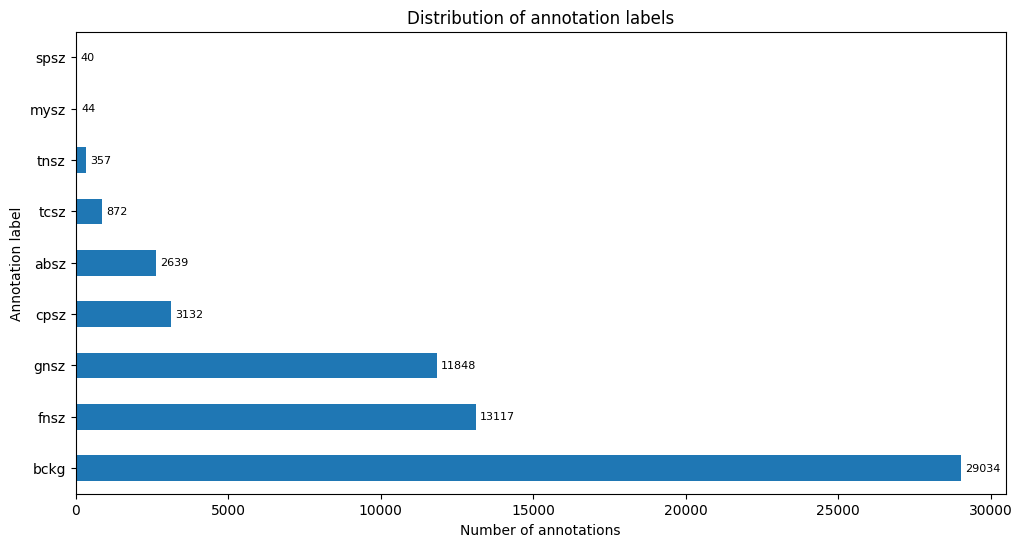

In [22]:
# Annotations distribution 
%matplotlib inline

data = data_sessions_corpus_df["label"].value_counts()
axes = pd.DataFrame(data).reset_index().plot.barh(
    x="label",
    rot=0,
    figsize=(12, 6),
    title=f"Distribution of annotation labels",
    xlabel=f"Number of annotations",
    ylabel="Annotation label",
    legend=False,
)

for container in axes.containers:
    axes.bar_label(container, label_type="edge", fontsize=8, padding=3)
plt.show()


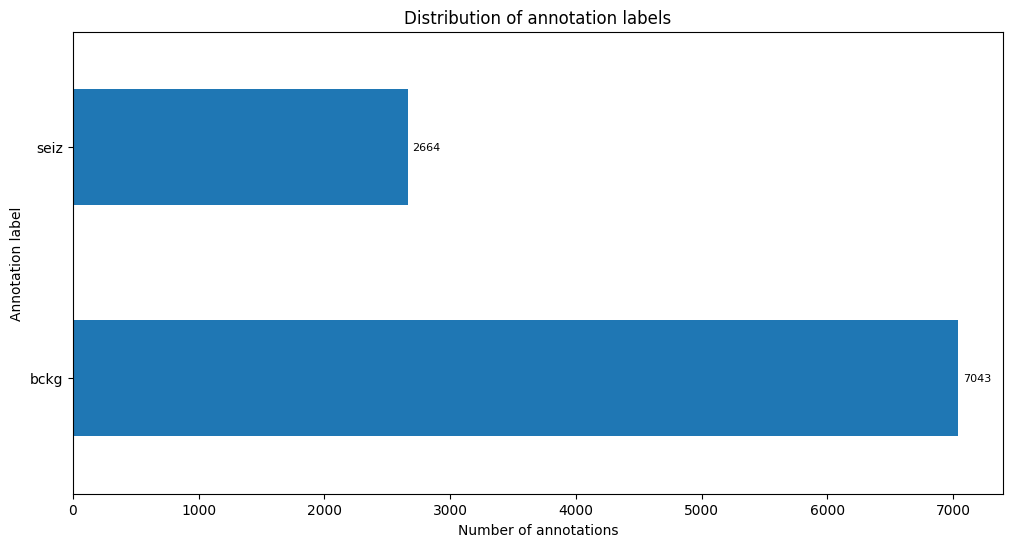

In [23]:
%matplotlib inline

data = data_sessions_corpus_df_binary["label"].value_counts()
axes = pd.DataFrame(data).reset_index().plot.barh(
    x="label",
    rot=0,
    figsize=(12, 6),
    title=f"Distribution of annotation labels",
    xlabel=f"Number of annotations",
    ylabel="Annotation label",
    legend=False,
)

for container in axes.containers:
    axes.bar_label(container, label_type="edge", fontsize=8, padding=3)
plt.show()

Según la información de la tabla, el dataset está balanceado (desbalance clásico), favoreciendo el aprendizaje de los artefactos "bckg" si no se analiza la información.

In [24]:
# Data correlation, annotations per session 
data_sessions_corpus_df["RecordID"] = (
    data_sessions_corpus_df["Patient"] + "_" +
    data_sessions_corpus_df["Session"] + "_" +
    data_sessions_corpus_df["Section"]
)
data_sessions_corpus_df["Tokens"] = (
    data_sessions_corpus_df["label"]
    .str.split("_")
)

data_sessions_corpus_df["NLabels"] = (
    data_sessions_corpus_df["Tokens"]
    .str.len()
)

print("\n>> Count of different labels by session")
print(data_sessions_corpus_df["NLabels"].value_counts())

SEIZURE_TOKENS = set().union(*SEIZURE_KEYWORDS.values())

data_sessions_corpus_df["HasSeizure"] = (
    data_sessions_corpus_df["Tokens"]
    .apply(lambda x: any(label in SEIZURE_TOKENS for label in x))
)

ARTIFACT_TOKENS = set().union(*ARTIFACT_KEYWORDS.values())

data_sessions_corpus_df["HasArtifact"] = (
    data_sessions_corpus_df["Tokens"]
    .apply(lambda x: any(label in ARTIFACT_TOKENS for label in x))
)

record_summary = (
    data_sessions_corpus_df
    .groupby("RecordID")
    .agg({
        "HasArtifact":"max",
        "HasSeizure":"max"
    })
)

print("\n>> Count of records with artifacts and seizures by session")
print(record_summary.value_counts())

#SEIZURE_KEYWORDS['bckg'] = {'bckg'}


>> Count of different labels by session
NLabels
1    61083
Name: count, dtype: int64

>> Count of records with artifacts and seizures by session
HasArtifact  HasSeizure
False        False         7043
             True          1097
Name: count, dtype: int64


Según los datos obtenidos se puede distribuir la información para tener suficientes datos para cada subclase según las características comunes, en el siguiente segmento se propone una distribución de las 19 clases disponibles teniendo en cuenta la cantidad de información de cada segmento.

#### Annotations categorization and window generation

In [26]:
# Neutral label
BACKGROUND_LABEL = "bckg"
SEIZURE_TOKENS_BY = set().union(*SEIZURE_KEYWORKDS_BY.values())

```
t0 = time.time()
segments_df = label_windows(data_sessions_corpus_df, window_size_sec=1)
print(f"{time.time()-t0:.2f}s para {len(segments_df)} ventanas totales")

t0 = time.time()
segments_df_binary = label_windows(data_sessions_corpus_df_binary, window_size_sec=1, binary=True)
print(f"{time.time()-t0:.2f}s para {len(segments_df_binary)} ventanas totales")
```

In [27]:
from functools import lru_cache
from collections import defaultdict
import numpy as np
import time

# Cache: cada label se tokeniza una sola vez
@lru_cache(maxsize=None)
def split_compound_label(label):
    return frozenset(label.lower().split("_"))


def label_windows(annotations_df, window_size_sec, binary=False):
    group_cols = ["Patient", "Session", "Section", "Montage"]

    observed_tokens = set().union(
        *(split_compound_label(l) for l in annotations_df["label"].dropna().unique())
    )

    label_groups = (
        {"seiz": {"seiz"}, "bckg": {BACKGROUND_LABEL}}
        if binary
        else dict(SEIZURE_KEYWORDS)
    )

    seizure_tokens = set().union(*SEIZURE_KEYWORDS.values())
    if "seiz" in observed_tokens:
        seizure_tokens.add("seiz")

    # Cache de flags por combinación de labels (se repiten muchísimo)
    @lru_cache(maxsize=None)
    def flags_for(raw_labels):
        all_tokens = set()
        for lbl in raw_labels:
            all_tokens |= split_compound_label(lbl)

        out = {g: int(bool(all_tokens & kw)) for g, kw in label_groups.items()}

        cats = [
            {g for g, kw in label_groups.items() if split_compound_label(l) & kw}
            for l in raw_labels
        ]
        genuine = any(len(c) > 1 for c in cats)
        n_present = sum(out.values())
        has_seiz = int(bool(all_tokens & seizure_tokens))

        out["genuine_cooccurrence"] = int(genuine)
        out["weak_overlap"] = int(n_present > 1 and not genuine)
        out["has_seizure_activity"] = has_seiz
        out["has_no_annotation"] = int(len(all_tokens) == 0)
        out["is_background"] = int(BACKGROUND_LABEL in all_tokens and not has_seiz)
        return out

    rows = []
    for keys, g in annotations_df.groupby(group_cols):
        patient, session, section, montage = keys
        n_windows = int(g["stop_time"].max() // window_size_sec)
        if n_windows == 0:
            continue

        win_labels = defaultdict(list)
        win_channels = defaultdict(set)

        for s, e, lbl, ch in zip(
            g["start_time"].to_numpy(),
            g["stop_time"].to_numpy(),
            g["label"].to_numpy(),
            g["channel"].to_numpy(),
        ):
            if lbl != lbl or lbl is None:  # NaN
                continue
            w0 = int(s // window_size_sec)
            w1 = min(int(np.ceil(e / window_size_sec)), n_windows)  # exclusivo
            for w in range(w0, w1):
                win_labels[w].append(lbl)
                win_channels[w].add(ch)

        for w in range(n_windows):
            raw_labels = list(dict.fromkeys(win_labels.get(w, ())))
            row = {
                "Patient": patient,
                "Session": session,
                "Section": section,
                "Montage": montage,
                "raw_labels": raw_labels,
                "n_channels_annotated": len(win_channels.get(w, ())),
                "window_size": window_size_sec,
                "start": w * window_size_sec,
                "end": (w + 1) * window_size_sec,
            }
            row.update(flags_for(tuple(raw_labels)))
            rows.append(row)

    return pd.DataFrame(rows)

In [28]:
t0 = time.time()
segments_df = label_windows(data_sessions_corpus_df, window_size_sec=1)
print(f"{time.time()-t0:.2f}s para {len(segments_df)} ventanas totales")

49.40s para 875168 ventanas totales


In [29]:
t0 = time.time()
segments_df_binary = label_windows(data_sessions_corpus_df_binary, window_size_sec=1, binary=True)
print(f"{time.time()-t0:.2f}s para {len(segments_df_binary)} ventanas totales")

21.66s para 823149 ventanas totales


In [30]:
# Guárdalo para no repetir el cálculo
segments_df.to_parquet("segments_1s.parquet")
segments_df_binary.to_parquet("segments_1s_binary.parquet")

In [31]:
# Visualization
display(segments_df.head(50))

,Patient,Session,Section,Montage,raw_labels,n_channels_annotated,window_size,start,end,focal,generalized_toniclonic,genuine_cooccurrence,weak_overlap,has_seizure_activity,has_no_annotation,is_background
0,aaaaaaac,s001,t000,02_tcp_le,[],0,1,0,1,0,0,0,0,0,1,0
1,aaaaaaac,s001,t000,02_tcp_le,[],0,1,1,2,0,0,0,0,0,1,0
2,aaaaaaac,s001,t000,02_tcp_le,[],0,1,2,3,0,0,0,0,0,1,0
3,aaaaaaac,s001,t000,02_tcp_le,[],0,1,3,4,0,0,0,0,0,1,0
4,aaaaaaac,s001,t000,02_tcp_le,[],0,1,4,5,0,0,0,0,0,1,0
5,aaaaaaac,s001,t000,02_tcp_le,[],0,1,5,6,0,0,0,0,0,1,0
6,aaaaaaac,s001,t000,02_tcp_le,[],0,1,6,7,0,0,0,0,0,1,0
7,aaaaaaac,s001,t000,02_tcp_le,[],0,1,7,8,0,0,0,0,0,1,0
8,aaaaaaac,s001,t000,02_tcp_le,[],0,1,8,9,0,0,0,0,0,1,0
9,aaaaaaac,s001,t000,02_tcp_le,[],0,1,9,10,0,0,0,0,0,1,0


In [32]:
# Visualization
display(segments_df_binary.head(50))

,Patient,Session,Section,Montage,raw_labels,n_channels_annotated,window_size,start,end,seiz,bckg,genuine_cooccurrence,weak_overlap,has_seizure_activity,has_no_annotation,is_background
0,aaaaaaac,s001,t000,02_tcp_le,[],0,1,0,1,0,0,0,0,0,1,0
1,aaaaaaac,s001,t000,02_tcp_le,[],0,1,1,2,0,0,0,0,0,1,0
2,aaaaaaac,s001,t000,02_tcp_le,[],0,1,2,3,0,0,0,0,0,1,0
3,aaaaaaac,s001,t000,02_tcp_le,[],0,1,3,4,0,0,0,0,0,1,0
4,aaaaaaac,s001,t000,02_tcp_le,[],0,1,4,5,0,0,0,0,0,1,0
5,aaaaaaac,s001,t000,02_tcp_le,[],0,1,5,6,0,0,0,0,0,1,0
6,aaaaaaac,s001,t000,02_tcp_le,[],0,1,6,7,0,0,0,0,0,1,0
7,aaaaaaac,s001,t000,02_tcp_le,[],0,1,7,8,0,0,0,0,0,1,0
8,aaaaaaac,s001,t000,02_tcp_le,[],0,1,8,9,0,0,0,0,0,1,0
9,aaaaaaac,s001,t000,02_tcp_le,[],0,1,9,10,0,0,0,0,0,1,0


In [33]:
# Porcentaje de ventanas sin anotaciones superpuestas
print("\n>> Porcentaje de ventanas sin anotación superpuesta")
print(f"{segments_df['has_no_annotation'].mean() * 100:.2f} %")


>> Porcentaje de ventanas sin anotación superpuesta
38.02 %


In [34]:
# Porcentaje de ventanas sin anotaciones superpuestas
print("\n>> Porcentaje de ventanas sin anotación superpuesta")
print(f"{segments_df_binary['has_no_annotation'].mean() * 100:.2f} %")


>> Porcentaje de ventanas sin anotación superpuesta
47.19 %


In [35]:
## Results analysis  for windowing
print("\n>> Analysis of annotations according to windows of 1s to all corpus")
display(
    segments_df.loc[
        (segments_df["Patient"] == "aaaaaaac") &
        (segments_df["Session"] == "s001")
    ].head(50)
)

# Manual visualization
sample = data_sessions_corpus_df[
    (data_sessions_corpus_df["Patient"]=="aaaaaaac") &
    (data_sessions_corpus_df["Session"]=="s001")
]
print("\n>> Manual correlation to verify data")
print(sample[["channel","start_time","stop_time","label"]])


>> Analysis of annotations according to windows of 1s to all corpus


,Patient,Session,Section,Montage,raw_labels,n_channels_annotated,window_size,start,end,focal,generalized_toniclonic,genuine_cooccurrence,weak_overlap,has_seizure_activity,has_no_annotation,is_background
0,aaaaaaac,s001,t000,02_tcp_le,[],0,1,0,1,0,0,0,0,0,1,0
1,aaaaaaac,s001,t000,02_tcp_le,[],0,1,1,2,0,0,0,0,0,1,0
2,aaaaaaac,s001,t000,02_tcp_le,[],0,1,2,3,0,0,0,0,0,1,0
3,aaaaaaac,s001,t000,02_tcp_le,[],0,1,3,4,0,0,0,0,0,1,0
4,aaaaaaac,s001,t000,02_tcp_le,[],0,1,4,5,0,0,0,0,0,1,0
5,aaaaaaac,s001,t000,02_tcp_le,[],0,1,5,6,0,0,0,0,0,1,0
6,aaaaaaac,s001,t000,02_tcp_le,[],0,1,6,7,0,0,0,0,0,1,0
7,aaaaaaac,s001,t000,02_tcp_le,[],0,1,7,8,0,0,0,0,0,1,0
8,aaaaaaac,s001,t000,02_tcp_le,[],0,1,8,9,0,0,0,0,0,1,0
9,aaaaaaac,s001,t000,02_tcp_le,[],0,1,9,10,0,0,0,0,0,1,0



>> Manual correlation to verify data
      channel  start_time  stop_time label
16247  FP1-F7     36.8868   183.3055  cpsz
16248   F7-T3     36.8868   183.3055  cpsz
16249   T3-T5     36.8868   183.3055  cpsz
16250   T5-O1     36.8868   183.3055  cpsz
16251  FP2-F8     36.8868   183.3055  cpsz


In [36]:
## Results analysis for windowing
print("\n>> Analysis of annotations according to windows of 1s to all corpus")
display(
    segments_df_binary.loc[
        (segments_df_binary["Patient"] == "aaaaaaac") &
        (segments_df_binary["Session"] == "s001")
    ].head(50)
)


# Manual visualization
sample_by = data_sessions_corpus_df_binary[
    (data_sessions_corpus_df_binary["Patient"]=="aaaaaaac") &
    (data_sessions_corpus_df_binary["Session"]=="s001")
]
print("\n>> Manual correlation to verify data")
print(sample_by[["channel","start_time","stop_time","label"]])


>> Analysis of annotations according to windows of 1s to all corpus


,Patient,Session,Section,Montage,raw_labels,n_channels_annotated,window_size,start,end,seiz,bckg,genuine_cooccurrence,weak_overlap,has_seizure_activity,has_no_annotation,is_background
0,aaaaaaac,s001,t000,02_tcp_le,[],0,1,0,1,0,0,0,0,0,1,0
1,aaaaaaac,s001,t000,02_tcp_le,[],0,1,1,2,0,0,0,0,0,1,0
2,aaaaaaac,s001,t000,02_tcp_le,[],0,1,2,3,0,0,0,0,0,1,0
3,aaaaaaac,s001,t000,02_tcp_le,[],0,1,3,4,0,0,0,0,0,1,0
4,aaaaaaac,s001,t000,02_tcp_le,[],0,1,4,5,0,0,0,0,0,1,0
5,aaaaaaac,s001,t000,02_tcp_le,[],0,1,5,6,0,0,0,0,0,1,0
6,aaaaaaac,s001,t000,02_tcp_le,[],0,1,6,7,0,0,0,0,0,1,0
7,aaaaaaac,s001,t000,02_tcp_le,[],0,1,7,8,0,0,0,0,0,1,0
8,aaaaaaac,s001,t000,02_tcp_le,[],0,1,8,9,0,0,0,0,0,1,0
9,aaaaaaac,s001,t000,02_tcp_le,[],0,1,9,10,0,0,0,0,0,1,0



>> Manual correlation to verify data
     channel  start_time  stop_time label
3553    TERM     36.8868   237.2101  seiz
3554    TERM     12.0764   200.3233  seiz


In [37]:
data_sessions_corpus_df["label"]
data_sessions_corpus_df["label"].value_counts()
data_sessions_corpus_df.groupby("label")["WindowSize"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
absz,2639.0,8.560884,4.991428,2.3640,5.101300,6.5743,9.80000,24.8962
bckg,29034.0,280.330465,343.297184,0.1000,1.215925,141.0221,461.50195,1676.0000
cpsz,3132.0,82.102704,117.966529,2.3355,38.582800,65.3718,95.96440,1303.0000
fnsz,13117.0,53.466449,94.688750,0.0000,16.000000,27.1452,58.34020,1720.7640
gnsz,11848.0,61.259390,108.120549,3.3050,16.053600,31.7114,60.93660,1161.9329
mysz,44.0,646.435864,40.903346,606.0000,606.000000,646.4345,686.86900,686.8890
spsz,40.0,68.421545,15.899905,45.8122,56.221000,63.0828,83.13810,97.0608
tcsz,872.0,61.827318,32.316092,12.8930,45.032000,56.3440,77.85400,310.9645
tnsz,357.0,28.928169,31.163790,5.7697,17.000000,20.3984,26.39840,146.8889


In [38]:
print(">> Labels")
display(data_sessions_corpus_df_binary["label"])
print(">> Counts")
display(data_sessions_corpus_df_binary["label"].value_counts())
print(">> Labels by windows")
display(data_sessions_corpus_df_binary.groupby("label")["WindowSize"].describe())

>> Labels


0       seiz
1       seiz
2       seiz
3       seiz
4       seiz
        ... 
9702    bckg
9703    bckg
9704    bckg
9705    bckg
9706    bckg
Name: label, Length: 9707, dtype: str

>> Counts


label
bckg    7043
seiz    2664
Name: count, dtype: int64

>> Labels by windows


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
bckg,7043.0,37.642931,158.454161,0.1,0.9806,1.00000,1.031400,1646.000
seiz,2664.0,63.856042,105.405062,0.0,16.9697,34.93835,75.106925,1720.764


Seizure labels according to classification


,Windows,Percentage
focal,125451,72.51
generalized_toniclonic,47561,27.49


Seizure labels according to labels


,Windows,Percentage
absz,1144,0.66
cpsz,29625,17.12
fnsz,95209,55.03
gnsz,41692,24.10
mysz,1293,0.75
spsz,617,0.36
tcsz,2892,1.67
tnsz,540,0.31


Seizure labels according to labels


,Windows,Percentage
focal,125451,72.51
generalized_toniclonic,47561,27.49



>> Patients and label distribution


focal                     168
generalized_toniclonic    110
dtype: int64

focal                     34.847500
generalized_toniclonic    13.211389
Name: Hours, dtype: float64


>> Windows per patient distribution


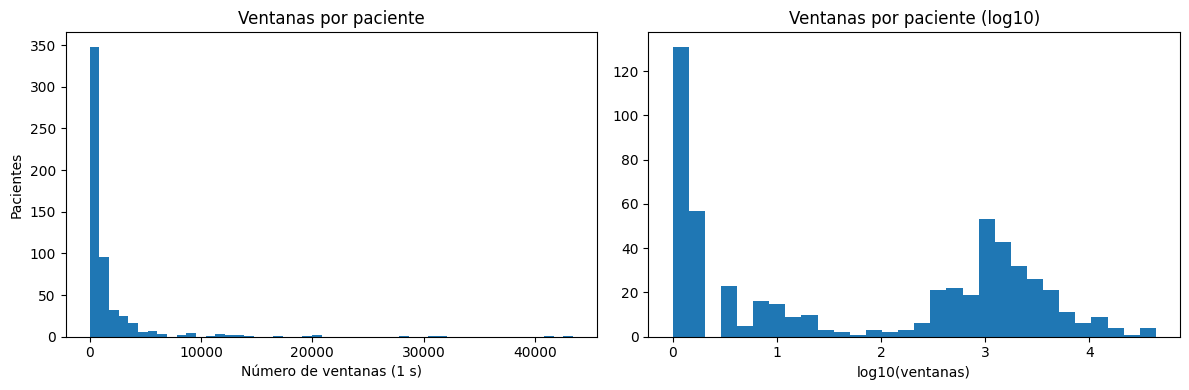

In [39]:
# Dataset balance by new labels (not fixed 19)
seizure_counts = segments_df[list(SEIZURE_KEYWORDS.keys())].sum()

seizure_percent = (
    seizure_counts / seizure_counts.sum() * 100
).round(2)

print("Seizure labels according to classification")
display(pd.DataFrame({
    "Windows": seizure_counts,
    "Percentage": seizure_percent
}))

seizure_counts_lab = pd.Series({
    token: segments_df["raw_labels"].map(
        lambda labels: any(token in split_compound_label(label) for label in labels)
    ).sum()
    for token in sorted(SEIZURE_TOKENS)
})

seizure_percent_lab = (
    seizure_counts_lab / seizure_counts_lab.sum() * 100
).round(2)

print("Seizure labels according to labels")
display(pd.DataFrame({
    "Windows": seizure_counts_lab,
    "Percentage": seizure_percent_lab
}))

seizure_percent_lab = (
    seizure_counts_lab / seizure_counts_lab.sum() * 100
).round(2)

print("Seizure labels according to labels")
display(pd.DataFrame({
    "Windows": seizure_counts,
    "Percentage": seizure_percent
}))

# Patients per label
print("\n>> Patients and label distribution")
patients_per_class = {
    seizure:
        segments_df.loc[
            segments_df[seizure] == 1,
            "Patient"
        ].nunique()
    for seizure in SEIZURE_KEYWORDS
}
display(pd.Series(patients_per_class))

# Duration per label
duration = seizure_counts / 3600
display(duration.rename("Hours"))

# Original annotations duration
data_sessions_corpus_df.groupby("label")["WindowSize"].describe()

# Windows per patient
print("\n>> Windows per patient distribution")
windows_per_patient = (
    segments_df.groupby("Patient").size()
)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

windows_per_patient.plot.hist(bins=50, ax=ax[0])
ax[0].set_title("Ventanas por paciente")
ax[0].set_xlabel("Número de ventanas (1 s)")
ax[0].set_ylabel("Pacientes")

ax[1].hist(np.log10(windows_per_patient), bins=30)
ax[1].set_title("Ventanas por paciente (log10)")
ax[1].set_xlabel("log10(ventanas)")

plt.tight_layout()
plt.show()


>> Keywords distribution


,Windows,Percentage
seiz,171652,39.49
bckg,263030,60.51



>> Label distribution


seiz    238
bckg    490
dtype: int64

seiz    47.681111
bckg    73.063889
Name: Hours, dtype: float64


>> Windows per patient distribution


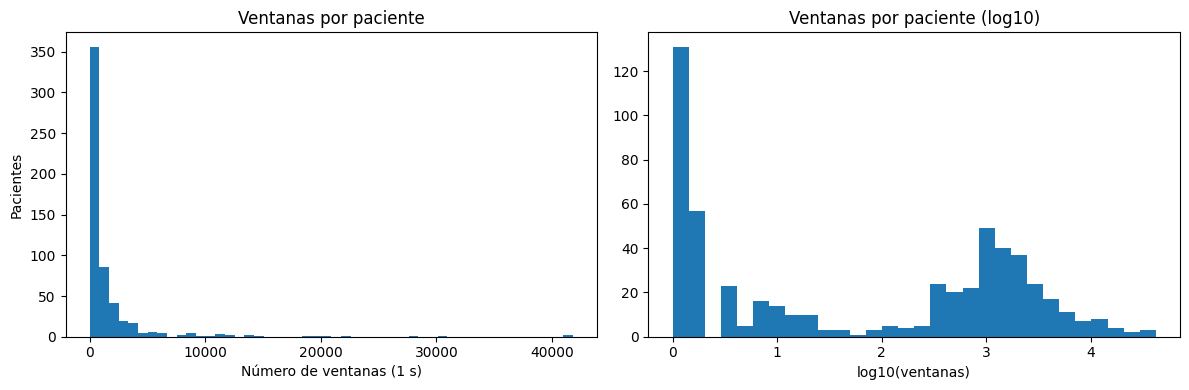

In [40]:
# Dataset balance by new labels (not 19)
# Add binary label flags from each window's raw labels
binary_window_labels = segments_df_binary["raw_labels"].map(set)
segments_df_binary["seiz"] = binary_window_labels.map(lambda labels: "seiz" in labels).astype(int)
segments_df_binary["bckg"] = binary_window_labels.map(lambda labels: "bckg" in labels).astype(int)

# Dataset balance
seizure_counts = segments_df_binary[["seiz", "bckg"]].sum()

seizure_percent = (
    seizure_counts / seizure_counts.sum() * 100
).round(2)

print("\n>> Keywords distribution")
display(pd.DataFrame({
    "Windows": seizure_counts,
    "Percentage": seizure_percent
}))

# Patients per label
print("\n>> Label distribution")
patients_per_class = {
    label: segments_df_binary.loc[
        segments_df_binary[label] == 1, "Patient"
    ].nunique()
    for label in ["seiz", "bckg"]
}
display(pd.Series(patients_per_class))

# Duration per label
duration = seizure_counts / 3600
display(duration.rename("Hours"))

# Original annotations duration
data_sessions_corpus_df_binary.groupby("label")["WindowSize"].describe()

# Windows per patient
print("\n>> Windows per patient distribution")
windows_per_patient = (
    segments_df_binary.groupby("Patient").size()
)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

windows_per_patient.plot.hist(bins=50, ax=ax[0])
ax[0].set_title("Ventanas por paciente")
ax[0].set_xlabel("Número de ventanas (1 s)")
ax[0].set_ylabel("Pacientes")

ax[1].hist(np.log10(windows_per_patient), bins=30)
ax[1].set_title("Ventanas por paciente (log10)")
ax[1].set_xlabel("log10(ventanas)")

plt.tight_layout()
plt.show()

In [41]:
df = segments_df_binary

# 1. Calidad de la ventana
print(">> Calidad de ventanas (%)")
display(pd.Series({
    "solo seiz": ((df.seiz == 1) & (df.bckg == 0)).mean(),
    "solo bckg": ((df.seiz == 0) & (df.bckg == 1)).mean(),
    "ambos":     ((df.seiz == 1) & (df.bckg == 1)).mean(),
    "ninguno":   ((df.seiz == 0) & (df.bckg == 0)).mean(),
}).mul(100).round(2))

# 2. Balance sobre ventanas únicas (con prioridad a seiz)
df = df.assign(y=(df.seiz == 1).astype(int))
print(">> Balance (seiz vs resto)")
display(df["y"].value_counts(normalize=True).mul(100).round(2))

known = (
    (segments_df_binary["seiz"] == 1)
    | (segments_df_binary["bckg"] == 1)
)

df_known = segments_df_binary.loc[known].copy()
df_known["y"] = df_known["has_seizure_activity"]

display(
    df_known["y"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# 3. Ventanas de crisis por paciente
per_patient = df.groupby("Patient").agg(total=("y", "size"), seiz=("y", "sum"))
per_patient["seiz_ratio"] = per_patient["seiz"] / per_patient["total"]
print(f">> Pacientes con crisis: {(per_patient.seiz > 0).sum()} / {len(per_patient)}")
display(per_patient[per_patient.seiz > 0]["seiz"].describe())

# 4. Concentración
top = per_patient["seiz"].sort_values(ascending=False)
print(f">> Top 10 pacientes aportan {top.head(10).sum() / top.sum() * 100:.1f}% de las ventanas seiz")

>> Calidad de ventanas (%)


solo seiz    20.85
solo bckg    31.95
ambos         0.00
ninguno      47.19
dtype: float64

>> Balance (seiz vs resto)


y
0    79.15
1    20.85
Name: proportion, dtype: float64

y
0    60.51
1    39.49
Name: proportion, dtype: float64

>> Pacientes con crisis: 238 / 558


count     238.000000
mean      721.226891
std      1206.990986
min         4.000000
25%        71.500000
50%       239.000000
75%       842.500000
max      8934.000000
Name: seiz, dtype: float64

>> Top 10 pacientes aportan 29.9% de las ventanas seiz


In [42]:
from sklearn.model_selection import StratifiedGroupKFold

pp = per_patient.reset_index()
pp["has_seiz"] = (pp.seiz > 0).astype(int)

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
df["fold"] = -1
for k, (_, test_idx) in enumerate(sgkf.split(df, df["y"], groups=df["Patient"])):
    df.iloc[test_idx, df.columns.get_loc("fold")] = k

display(df.groupby("fold").agg(
    windows=("y", "size"),
    seiz=("y", "sum"),
    patients=("Patient", "nunique"),
).assign(seiz_pct=lambda t: (t.seiz / t.windows * 100).round(2)))

,windows,seiz,patients,seiz_pct
fold,,,,
0,162607,33370,196,20.52
1,163667,33694,53,20.59
2,170346,37270,64,21.88
3,163926,33947,55,20.71
4,162603,33371,190,20.52


### Corpus splitter analysis 

In [43]:
# Data extraction
seg = segments_df.copy()
seg["is_positive"] = seg["has_seizure_activity"].astype(int)
pats = set(seg["Patient"])
print(f">> {len(seg)} ventanas | {len(pats)} pacientes | {seg['is_positive'].sum()} positivas")

# Splitter (forced=None -> real division)
out, assignment, report = grouped_split_from_labels(
    seg, "is_positive", size_weight=0.5, forced=None
)
print("\n>> Reporte del splitter")
display(report)

# Sanity check
assert out["split"].notna().all(), "Hay ventanas sin split"
assert (out.groupby("Patient")["split"].nunique() == 1).all(), "Paciente en más de un split"
assert out["is_positive"].sum() == seg["is_positive"].sum(), "Se perdieron positivos"
assert set(out["split"].unique()) <= {"train", "val", "test"}, "Nombres de split inesperados"
print("\n[OK] Integridad: splits disjuntos, sin pérdida de positivos, nombres válidos")

# Registry comparison
reg = load_registry(REG_PATH)
folder = forced_for(reg, pats, source_prefix="folder:")
any_rule = forced_for(reg, pats)
bad = {p: (s, assignment[p]) for p, s in any_rule.items() if assignment[p] != s}
assert not bad, f"Registro no respetado: {list(bad.items())[:5]}"

print(f"\n>> Pacientes con regla de carpeta: {len(folder)} / {len(pats)}")
print(f">> Con cualquier regla del registro: {len(any_rule)} / {len(pats)}")
sin_regla = pats - set(any_rule)
print(f">> Sin regla (repartidos por el splitter): {len(sin_regla)}")
if sin_regla:
    print("   ejemplos:", sorted(sin_regla)[:10])
print(">> Distribución según registro:", pd.Series(folder).value_counts().to_dict())
print("[OK] El splitter respeta el registro")

# Real balance
bal = split_balance_report(out)
bal["pct_ventanas"] = (bal["n_total"] / bal["n_total"].sum() * 100).round(2)
bal["pct_positivos"] = (bal["n_positive"] / bal["n_positive"].sum() * 100).round(2)
bal["horas_seiz"] = (bal["n_positive"] / 3600).round(2)
print("\n>> Balance por split")
display(bal.round(4))

# Crisis patients and split concentration
pp = out.groupby(["split", "Patient"])["is_positive"].agg(total="size", seiz="sum").reset_index()
resumen = pp.groupby("split").agg(
    pacientes=("Patient", "nunique"),
    con_crisis=("seiz", lambda s: (s > 0).sum()),
)
resumen["top5_pct_seiz"] = [
    round(g["seiz"].nlargest(5).sum() / max(g["seiz"].sum(), 1) * 100, 1)
    for _, g in pp.groupby("split")
]
print("\n>> Pacientes con crisis y concentración (top 5) por split")
display(resumen)

#
_, assignment2, _ = grouped_split_from_labels(
    seg, "is_positive", size_weight=0.5, forced=None
)
assert assignment == assignment2, "El splitter no es determinista"
print("\n[OK] Determinista con la misma seed")

# Cache
with tempfile.TemporaryDirectory() as tmp:
    kw = dict(group_col="Patient", size_weight=0.5,
              dataset_division_dir=tmp, version=1, target="nb_test")
    a, asg_a, _ = get_or_compute_labeled_split(seg, "is_positive", **kw)
    b, asg_b, _ = get_or_compute_labeled_split(seg, "is_positive", **kw)
    assert asg_a == asg_b, "El caché devolvió otra asignación"
    assert a["split"].reset_index(drop=True).equals(b["split"].reset_index(drop=True))
    assert asg_a == assignment, "Caché y split directo difieren"
print("[OK] Caché consistente")

>> 875168 ventanas | 558 pacientes | 171873 positivas
[INFO] Fixed per register: 558 / 558 patients.

>> Reporte del splitter


,n_positive,n_patients
train,120705.0,463
val,27056.0,52
test,24112.0,43



[OK] Integridad: splits disjuntos, sin pérdida de positivos, nombres válidos

>> Pacientes con regla de carpeta: 558 / 558
>> Con cualquier regla del registro: 558 / 558
>> Sin regla (repartidos por el splitter): 0
>> Distribución según registro: {'train': 463, 'val': 52, 'test': 43}
[OK] El splitter respeta el registro

>> Balance por split


,n_total,n_positive,n_negative,positive_rate,pct_ventanas,pct_positivos,horas_seiz
split,,,,,,,
test,87731,24112,63619,0.2748,10.02,14.03,6.70
train,624051,120705,503346,0.1934,71.31,70.23,33.53
val,163386,27056,136330,0.1656,18.67,15.74,7.52



>> Pacientes con crisis y concentración (top 5) por split


,pacientes,con_crisis,top5_pct_seiz
split,,,
test,43,30,61.7
train,463,171,26.0
val,52,37,51.1


[INFO] Fixed per register: 558 / 558 patients.

[OK] Determinista con la misma seed
[INFO] Fixed per register: 558 / 558 patients.
[INFO] Existing split metadata does not match current configuration.
[INFO] Computing and saving new split...
[INFO] Saved new split to split_train70.0_val15.0_test15.0_p558_v1_nb_test_wNone_sNone_sw0.5_ua0.7
[INFO] Fixed per register: 558 / 558 patients.
[INFO] Loading existing split from split_train70.0_val15.0_test15.0_p558_v1_nb_test_wNone_sNone_sw0.5_ua0.7 parquet and json
[OK] Caché consistente


In [44]:
# Split real según la carpeta física de cada EDF (TUSZ: train / dev / eval)
FOLDER_TO_SPLIT = {"train": "train", "dev": "val", "eval": "test"}

def folder_split(path):
    for part in Path(path).parts:
        if part in FOLDER_TO_SPLIT:
            return FOLDER_TO_SPLIT[part]
    return None

sig = signal_sessions_corpus_df.assign(folder=lambda d: d["Path"].map(folder_split))
assert sig["folder"].notna().all(), "Hay EDFs fuera de train/dev/eval"

# Un paciente no debería estar en carpetas distintas
multi = sig.groupby("Patient")["folder"].nunique()
print("Pacientes en más de una carpeta:", (multi > 1).sum())

folder_truth = sig.groupby("Patient")["folder"].first().to_dict()

# Comparación independiente: carpetas físicas vs. assignment del splitter
comparables = {p: s for p, s in assignment.items() if p in folder_truth}
mismatch = {p: (folder_truth[p], s) for p, s in comparables.items() if folder_truth[p] != s}

print(f"Comparados: {len(comparables)} pacientes | discrepancias: {len(mismatch)}")
print("Sin carpeta conocida:", set(assignment) - set(folder_truth))
assert not mismatch, list(mismatch.items())[:10]

# Distribución por carpeta, para contrastar con lo esperado del registro
print(pd.Series(comparables).value_counts().to_dict())
print(pd.Series(folder_truth).value_counts().to_dict(), "(todos los pacientes del EDA)")

assert not (multi > 1).any(), (
    "Hay pacientes en varias particiones; "
    "no se puede asignar su partición usando first()."
)

Pacientes en más de una carpeta: 0
Comparados: 558 pacientes | discrepancias: 0
Sin carpeta conocida: set()
{'train': 463, 'val': 52, 'test': 43}
{'train': 579, 'val': 53, 'test': 43} (todos los pacientes del EDA)


In [45]:
edf_p   = set(signal_sessions_corpus_df["Patient"])
csv_p   = set(data_sessions_corpus_df_binary["Patient"])
win_p   = set(segments_df_binary["Patient"])
seg_p   = set(seg["Patient"])

print(f"EDF: {len(edf_p)} | CSV_bi: {len(csv_p)} | ventanas: {len(win_p)} | seg (con anotación): {len(seg_p)}")
print("EDF sin CSV_bi:        ", len(edf_p - csv_p))
print("CSV_bi sin ventanas:   ", len(csv_p - win_p))
print("Ventanas sin anotación:", len(win_p - seg_p))

# Valores nulos en las claves de agrupación (groupby los descarta en silencio)
keys = ["Patient", "Session", "Section", "Montage"]
print(data_sessions_corpus_df_binary[keys].isna().sum())

EDF: 675 | CSV_bi: 675 | ventanas: 558 | seg (con anotación): 558
EDF sin CSV_bi:         0
CSV_bi sin ventanas:    117
Ventanas sin anotación: 0
Patient    0
Session    0
Section    0
Montage    0
dtype: int64


In [49]:
missing = set(data_sessions_corpus_df_binary["Patient"]) - set(segments_df_binary["Patient"])
m = data_sessions_corpus_df_binary[data_sessions_corpus_df_binary["Patient"].isin(missing)]

print(f"Pacientes faltantes: {len(missing)} | filas de anotación: {len(m)}")
print("stop_time NaN:", m["stop_time"].isna().sum())
display(m["stop_time"].describe())
display(m.groupby(["Patient", "Session", "Section", "Montage"])["stop_time"].max().describe())
print("Filas sin label:", m["label"].isna().sum())

# Prueba directa: recalcular solo estos pacientes
test = label_windows(m, window_size_sec=1, binary=True)
n_windows = int(g["stop_time"].max() // window_size_sec)

Pacientes faltantes: 117 | filas de anotación: 209
stop_time NaN: 0


count    209.000000
mean       0.897298
std        0.181617
min        0.311400
25%        0.954800
50%        0.975600
75%        0.986800
max        0.999000
Name: stop_time, dtype: float64

count    209.000000
mean       0.897298
std        0.181617
min        0.311400
25%        0.954800
50%        0.975600
75%        0.986800
max        0.999000
Name: stop_time, dtype: float64

Filas sin label: 0


NameError: name 'annotations_df' is not defined